# Extra analysis for the v2 disease run (self-contained)

Run this **after** the main run has finished. It reads the saved results from Drive, so it does **not** need the main notebook's session, a GPU, or the training to be re-run. Use **Runtime → Run all** on a normal (CPU) Colab runtime.

| Cell | What it gives you |
|---|---|
| 2 | Corrected crop-shortcut analysis on the unseen set (replaces the wrong 0.0% figure) |
| 3 | Seen accuracy split by whether the image's source dataset was in training |
| 4 | The 21 image files whose size differs between the v1 and v2 Drive copies |

In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive"
cands = ["/content/DPD_Small_clean_v2", f"{DRIVE}/DPD_Small_clean_v2"]
DATA = next(p for p in cands if os.path.isfile(f"{p}/train.csv"))          # only the CSVs are needed here
RUN  = f"{DRIVE}/DPD_runs/v2/disease_independent_v2"
MODELS = ["ResNet50", "EfficientNet-B0", "ConvNeXt-Tiny"]
assert os.path.isdir(RUN), f"results folder not found: {RUN}"
print("CSVs from:", DATA); print("Results  :", RUN)

train, test_seen, test_unseen = (pd.read_csv(f"{DATA}/{n}.csv") for n in ["train", "test_seen", "test_unseen"])

# disease name <-> id (prediction files may hold names or ids; handle both)
name2id = {}
for df in (train, test_seen, test_unseen): name2id.update(dict(zip(df["disease"], df["disease_id"])))
id2name = {v: k for k, v in name2id.items()}
def to_id(x):
    try: return int(x)
    except (ValueError, TypeError): return name2id.get(str(x), -1)

def load_preds(model, split):
    p = pd.read_csv(f"{RUN}/{model}_predictions_{split}.csv")
    tc = next((c for c in ["true", "true_id", "y_true", "label", "target"] if c in p.columns), None)
    assert tc, f"true-label column not found in {p.columns.tolist()}"
    p = p.rename(columns={tc: "true_label"})
    p["true_id"], p["pred_id"] = p["true_label"].map(to_id), p["pred1"].map(to_id)
    p["correct"] = p["true_id"] == p["pred_id"]
    unmapped = int((p.true_id < 0).sum() + (p.pred_id < 0).sum())
    print(f"{model:16s} {split:7s} n={len(p):5d}  Top-1={p.correct.mean()*100:5.2f}%  unmapped labels={unmapped}")
    return p

print("\nSanity check: these Top-1 values should match your results table "
      "(seen 65.05/64.85/64.30, unseen 8.63/8.91/14.09):")
for m in MODELS:
    load_preds(m, "seen"); load_preds(m, "unseen")
print("\nFirst rows of one prediction file:"); display(pd.read_csv(f"{RUN}/ConvNeXt-Tiny_predictions_unseen.csv").head(3))

Mounted at /content/drive
CSVs from: /content/drive/MyDrive/DPD_Small_clean_v2
Results  : /content/drive/MyDrive/DPD_runs/v2/disease_independent_v2

Sanity check: these Top-1 values should match your results table (seen 65.05/64.85/64.30, unseen 8.63/8.91/14.09):
ResNet50         seen    n= 2000  Top-1=65.05%  unmapped labels=0
ResNet50         unseen  n= 1448  Top-1= 8.63%  unmapped labels=0
EfficientNet-B0  seen    n= 2000  Top-1=64.85%  unmapped labels=0
EfficientNet-B0  unseen  n= 1448  Top-1= 8.91%  unmapped labels=0
ConvNeXt-Tiny    seen    n= 2000  Top-1=64.30%  unmapped labels=0
ConvNeXt-Tiny    unseen  n= 1448  Top-1=14.09%  unmapped labels=0

First rows of one prediction file:


,path,true,pred1,pred2,pred3,pred4,pred5
0,images/CDDM_bell_pepper_bacterial_spot_41338.jpg,bacterial_spot,bacterial_spot,septoria_leaf_spot,black_rot,esca,spider_mites
1,images/CDDM_bell_pepper_bacterial_spot_41339.jpg,bacterial_spot,bacterial_spot,black_rot,target_spot,spider_mites,cedar_apple_rust
2,images/CDDM_bell_pepper_bacterial_spot_41340.jpg,bacterial_spot,bacterial_spot,target_spot,septoria_leaf_spot,black_rot,spider_mites


## 2. Corrected crop-shortcut analysis (unseen set)

ResNet50         unseen  n= 1448  Top-1= 8.63%  unmapped labels=0

=== ResNet50: 53.2% of wrong unseen predictions are a disease that was seen on the TRUE crop in training ===
Most frequent wrong predictions (true crop / true disease -> predicted disease):


count
true_crop   true_disease     pred_disease             
tomato      early_blight     septoria_leaf_spot    116
grape       black_rot        esca                  114
tomato      early_blight     late_blight            77
                             target_spot            59
cotton      bacterial_blight target_spot            55
pepper_bell bacterial_spot   target_spot            49
tomato      early_blight     bacterial_spot         42
mango       anthracnose      brown_spot             38

EfficientNet-B0  unseen  n= 1448  Top-1= 8.91%  unmapped labels=0

=== EfficientNet-B0: 56.6% of wrong unseen predictions are a disease that was seen on the TRUE crop in training ===
Most frequent wrong predictions (true crop / true disease -> predicted disease):


count
true_crop true_disease     pred_disease             
tomato    early_blight     late_blight           120
grape     black_rot        esca                  119
tomato    early_blight     septoria_leaf_spot     74
                           target_spot            44
cotton    bacterial_blight target_spot            38
tomato    early_blight     bacterial_spot         37
mango     anthracnose      peacock_spot           33
                           gall_midge             30

ConvNeXt-Tiny    unseen  n= 1448  Top-1=14.09%  unmapped labels=0

=== ConvNeXt-Tiny: 61.8% of wrong unseen predictions are a disease that was seen on the TRUE crop in training ===
Most frequent wrong predictions (true crop / true disease -> predicted disease):


count
true_crop true_disease     pred_disease             
grape     black_rot        esca                  144
tomato    early_blight     late_blight           114
                           bacterial_spot        101
                           septoria_leaf_spot     76
mango     anthracnose      peacock_spot           40
grape     black_rot        canker                 39
cotton    bacterial_blight target_spot            37
tomato    early_blight     target_spot            36

,model,wrong_unseen,pct_pred_disease_seen_on_true_crop
0,ResNet50,1323,53.2
1,EfficientNet-B0,1319,56.6
2,ConvNeXt-Tiny,1244,61.8



Unseen Top-1 (%) by number of crops the true disease has in train  (n_images in brackets for ConvNeXt):


,ResNet50,EfficientNet-B0,ConvNeXt-Tiny,n_images (ConvNeXt)
disease_n_train_crops,,,,
2,5.7,1.8,1.5,544
3,2.4,5.6,4.8,125
5,6.9,13.8,25.9,491
8,0.0,0.0,0.0,35
9,0.0,0.0,0.0,95
11,49.3,42.0,52.2,69
12,25.8,16.9,30.3,89


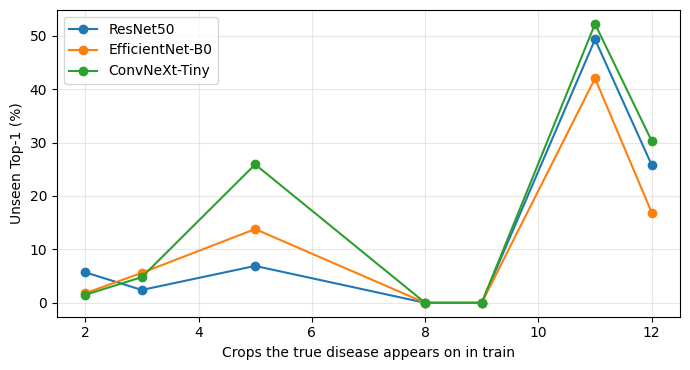

In [2]:
crops_per_disease = train.groupby("disease_id")["crop_id"].apply(set).to_dict()
meta = test_unseen[["path", "crop_id", "crop", "disease", "disease_n_train_crops"]].rename(
    columns={"crop": "true_crop", "disease": "true_disease"})

shortcut_rows, fig_data = [], {}
for m in MODELS:
    p = load_preds(m, "unseen").merge(meta, on="path", how="left")
    assert p["crop_id"].notna().all(), "predictions did not join to test_unseen.csv on 'path'"
    w = p[~p.correct].copy()
    w["pred_disease"] = w["pred_id"].map(id2name)
    w["same_crop_seen"] = [cr in crops_per_disease.get(pid, set()) for cr, pid in zip(w["crop_id"], w["pred_id"])]
    pct = w["same_crop_seen"].mean() * 100
    shortcut_rows.append({"model": m, "wrong_unseen": len(w), "pct_pred_disease_seen_on_true_crop": round(pct, 1)})

    print(f"\n=== {m}: {pct:.1f}% of wrong unseen predictions are a disease that was seen on the TRUE crop in training ===")
    print("Most frequent wrong predictions (true crop / true disease -> predicted disease):")
    display(w.groupby(["true_crop", "true_disease", "pred_disease"]).size().sort_values(ascending=False).head(8).rename("count").to_frame())

    by_n = p.groupby("disease_n_train_crops")["correct"].agg(["mean", "count"]).rename(columns={"mean": "top1", "count": "n_images"})
    by_n["top1"] = (by_n["top1"] * 100).round(1); fig_data[m] = by_n
    by_n.to_csv(f"{RUN}/{m}_unseen_by_n_train_crops.csv")
    p.groupby(["true_crop", "true_disease"])["correct"].agg(["mean", "count"]).assign(mean=lambda x: (x["mean"]*100).round(1)) \
        .rename(columns={"mean": "top1", "count": "n_images"}).to_csv(f"{RUN}/{m}_unseen_by_pair.csv")
    w.to_csv(f"{RUN}/{m}_unseen_wrong_predictions.csv", index=False)

summary = pd.DataFrame(shortcut_rows); display(summary)
summary.to_csv(f"{RUN}/unseen_shortcut_summary.csv", index=False)

print("\nUnseen Top-1 (%) by number of crops the true disease has in train  (n_images in brackets for ConvNeXt):")
tab = pd.concat({m: fig_data[m]["top1"] for m in MODELS}, axis=1); tab["n_images (ConvNeXt)"] = fig_data["ConvNeXt-Tiny"]["n_images"]
display(tab)
fig, ax = plt.subplots(figsize=(7, 3.8))
for m in MODELS: ax.plot(fig_data[m].index, fig_data[m]["top1"], marker="o", label=m)
ax.set_xlabel("Crops the true disease appears on in train"); ax.set_ylabel("Unseen Top-1 (%)"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{RUN}/unseen_acc_vs_n_train_crops.png", dpi=150); plt.show()

## 3. Seen accuracy by source (is the val → test drop a domain shift?)

In [3]:
rows = []
for m in MODELS:
    d = load_preds(m, "seen").merge(test_seen[["path", "source_in_train", "heldout_pair"]], on="path", how="left")
    for col in ["source_in_train", "heldout_pair"]:
        g = d.groupby(col)["correct"].agg(["mean", "count"])
        for k, r in g.iterrows():
            rows.append({"model": m, "group": f"{col}={k}", "top1": round(r["mean"] * 100, 1), "n": int(r["count"])})
res = pd.DataFrame(rows)
display(res.pivot(index="group", columns="model", values="top1"))
print("images per group:"); display(res[res.model == "ConvNeXt-Tiny"].set_index("group")["n"])
res.to_csv(f"{RUN}/seen_by_source_and_heldout.csv", index=False)

ResNet50         seen    n= 2000  Top-1=65.05%  unmapped labels=0
EfficientNet-B0  seen    n= 2000  Top-1=64.85%  unmapped labels=0
ConvNeXt-Tiny    seen    n= 2000  Top-1=64.30%  unmapped labels=0


model,ConvNeXt-Tiny,EfficientNet-B0,ResNet50
group,,,
heldout_pair=False,66.1,66.7,66.9
heldout_pair=True,5.0,5.0,5.0
source_in_train=False,73.3,73.3,66.7
source_in_train=True,64.1,64.7,65.0


images per group:


,n
group,
source_in_train=False,45
source_in_train=True,1955
heldout_pair=False,1940
heldout_pair=True,60


## 4. The 21 files that differ between the v1 and v2 Drive copies
Needs the two Drive image folders (it only lists and opens the files that differ). `mean_pixel_diff` near 0 means the file was only re-compressed; `CORRUPT` means the copy is unusable.

In [4]:
from PIL import Image
V1, V2 = f"{DRIVE}/DPD_Small_clean/images", f"{DRIVE}/DPD_Small_clean_v2/images"
def index(d): return {f: os.path.join(dp, f) for dp, _, fs in os.walk(d) for f in fs}
i1, i2 = index(V1), index(V2)
bad = [f for f in sorted(set(i1) & set(i2)) if os.path.getsize(i1[f]) != os.path.getsize(i2[f])]
print(f"v1 files {len(i1)} | v2 files {len(i2)} | overlap {len(set(i1) & set(i2))} | size differs: {len(bad)}")

in_splits = set()
for s in ["train", "val", "val_unseen", "test_seen", "test_unseen"]:
    in_splits |= {os.path.basename(x) for x in pd.read_csv(f"{DATA}/{s}.csv")["path"]}

def load(path):
    try:
        im = Image.open(path); im.load(); return im.convert("RGB")
    except Exception: return None
rows = []
for f in bad:
    a, b = load(i1[f]), load(i2[f])
    diff = (float(np.abs(np.asarray(a, dtype=np.int16) - np.asarray(b, dtype=np.int16)).mean())
            if a is not None and b is not None and a.size == b.size else None)
    rows.append({"file": f, "v1_bytes": os.path.getsize(i1[f]), "v2_bytes": os.path.getsize(i2[f]),
                 "v1_size": a.size if a else "CORRUPT", "v2_size": b.size if b else "CORRUPT",
                 "mean_pixel_diff": None if diff is None else round(diff, 2), "in_splits": f in in_splits})
chk = pd.DataFrame(rows); display(chk)
chk.to_csv(f"{RUN}/v1_v2_image_differences.csv", index=False)

v1 files 11443 | v2 files 3128 | overlap 3128 | size differs: 21


,file,v1_bytes,v2_bytes,v1_size,v2_size,mean_pixel_diff,in_splits
0,CDC_cassava_bacterial_blight_155.jpg,30007,29968,"(224, 224)","(224, 224)",1.17,True
1,CDC_cassava_brown_streak_disease_1366.jpg,34389,34416,"(224, 224)","(224, 224)",1.24,True
2,CDC_cassava_brown_streak_disease_790.jpg,35605,35624,"(224, 224)","(224, 224)",1.23,True
3,CDC_cassava_green_mite_1993.jpg,37382,37342,"(224, 224)","(224, 224)",1.30,True
4,CDC_cassava_mosaic_disease_3469.jpg,32845,32803,"(224, 224)","(224, 224)",1.25,True
5,CDC_cassava_mosaic_disease_3859.jpg,35645,35684,"(224, 224)","(224, 224)",1.32,True
6,CDC_cassava_mosaic_disease_3958.jpg,34997,34981,"(224, 224)","(224, 224)",1.32,True
7,CDC_cassava_mosaic_disease_4752.jpg,39103,39121,"(224, 224)","(224, 224)",1.33,True
8,CDC_cassava_mosaic_disease_4874.jpg,27291,27290,"(224, 224)","(224, 224)",1.10,True
9,CDC_cassava_mosaic_disease_4916.jpg,32261,32277,"(224, 224)","(224, 224)",1.29,True
